# 📰 NewsIQ — Synthetic Data Generation, Metadata Analysis & Fine-Tuned News Classification

## Project Overview

| Phase | Description |
|---|---|
| **Step 1** | Install dependencies |
| **Step 2** | Data Extraction — load 20 Newsgroups (10 categories) |
| **Step 3** | Synthetic Data Generation — via **Groq LLM API** (true article generation) |
| **Step 4** | Metadata Analysis — stats, visualisations, outlier filtering |
| **Step 5** | Prompt Design — few-shot + chain-of-thought classification prompt |
| **Step 6** | Fine-Tuning — DistilBERT on combined real + synthetic data |
| **Step 7** | Result Evaluation — classification report, confusion matrix, per-category accuracy |
| **Step 8** | Universal Q&A — any natural-language question routed to the **Groq LLM** |

### API Keys
- **Groq** (free): get your key at https://console.groq.com and store it as a Colab Secret named `GROQ_API_KEY` (or an environment variable). **Never paste it into the notebook.**
- No paid key needed — Groq's free tier is sufficient for this project.

In [ ]:
# ── Step 1: Install dependencies ──────────────────────────────────────────
!pip install -q transformers datasets evaluate scikit-learn nltk seaborn groq
print('✅ Dependencies installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.3/142.3 kB 8.2 MB/s eta 0:00:00
✅ Dependencies installed


In [ ]:
import os

# The Groq key is read from a Colab Secret or environment variable named GROQ_API_KEY.
# Never hard-code API keys in a notebook that will be committed to GitHub.
try:
    from google.colab import userdata
    GROQ_API_KEY = userdata.get('GROQ_API_KEY')
except Exception:
    GROQ_API_KEY = os.environ.get('GROQ_API_KEY', '')

if not GROQ_API_KEY:
    from getpass import getpass
    GROQ_API_KEY = getpass('Enter your Groq API key (input hidden): ')

assert GROQ_API_KEY, '❌ A Groq API key is required.'
print('✅ Groq API key loaded')


In [ ]:
# ── Step 2: Imports & Data Extraction ─────────────────────────────────────
import re, time, random, textwrap, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from groq import Groq
from datasets import Dataset
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, pipeline
)
import evaluate

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

# ── 10 representative categories ──
CATEGORIES = [
    'comp.graphics', 'comp.os.ms-windows.misc',
    'rec.sport.baseball', 'rec.motorcycles',
    'sci.med', 'sci.space',
    'talk.politics.misc', 'talk.religion.misc',
    'alt.atheism', 'misc.forsale'
]

newsgroups = fetch_20newsgroups(
    subset='all', categories=CATEGORIES,
    remove=('headers', 'footers', 'quotes')
)
TARGET_NAMES = newsgroups.target_names

df = pd.DataFrame({
    'text' : newsgroups.data,
    'label': newsgroups.target
})
df['topic'] = df['label'].map(lambda x: TARGET_NAMES[x])
df = df[df['text'].str.strip().astype(bool)].reset_index(drop=True)

print(f'✅ Extracted {len(df):,} real articles across {len(TARGET_NAMES)} categories')
print('   Categories:', ', '.join(TARGET_NAMES))

✅ Extracted 8,844 real articles across 10 categories
   Categories: alt.atheism, comp.graphics, comp.os.ms-windows.misc, misc.forsale, rec.motorcycles, rec.sport.baseball, sci.med, sci.space, talk.politics.misc, talk.religion.misc


In [ ]:
print('Displaying the first 5 rows with article text, numerical label, and category name:')
display(df[['text', 'label', 'topic']].head())

Displaying the first 5 rows with article text, numerical label, and category name:


,text,label,topic
0,\nMainly carbon dust with iron in a plastic bi...,6,sci.med
1,One last infield fly question that has always ...,5,rec.sport.baseball
2,The following is an introduction as to who is ...,9,talk.religion.misc
3,The Phillies were picked to be in first.\nSome...,5,rec.sport.baseball
4,Word for Windows lets me designate text as bei...,2,comp.os.ms-windows.misc


## Step 3 — Synthetic Data Generation via Groq LLM

Unlike simple synonym replacement, we use **llama-3.1-8b-instant** (Groq free tier) to generate
realistic, on-topic news articles for each category. This produces genuinely diverse training data.

In [ ]:
# ── Step 3: LLM-based Synthetic Article Generation ────────────────────────
groq_client = Groq(api_key=GROQ_API_KEY)
LLM_MODEL   = 'llama-3.1-8b-instant'   # free-tier Groq model

# Topic-specific context hints to guide generation quality
TOPIC_HINTS = {
    'comp.graphics'           : 'computer graphics, rendering, OpenGL, GPU shaders, image processing',
    'comp.os.ms-windows.misc' : 'Windows OS, registry, drivers, DLLs, Microsoft software bugs',
    'rec.sport.baseball'      : 'baseball games, pitching stats, batting averages, MLB teams',
    'rec.motorcycles'         : 'motorcycles, riding gear, maintenance, bike models, road trips',
    'sci.med'                 : 'medical research, drug trials, patient care, symptoms, treatment',
    'sci.space'               : 'space missions, NASA, satellites, planetary science, astronomy',
    'talk.politics.misc'      : 'US politics, policy debates, government, elections, legislation',
    'talk.religion.misc'      : 'religion, faith, theology, scripture, religious debate',
    'alt.atheism'             : 'atheism, secular humanism, arguments against religion, rationalism',
    'misc.forsale'            : 'classified ads, selling items, prices, condition, shipping info'
}

def generate_synthetic_article(topic: str, seed_text: str = '') -> str:
    """Ask the Groq LLM to generate one realistic newsgroup article for *topic*."""
    hint = TOPIC_HINTS.get(topic, topic)
    seed_snippet = f'\nFor inspiration, here is a real excerpt:\n"""{seed_text[:200]}"""' if seed_text else ''

    system_msg = (
        'You are a data-augmentation assistant for an NLP research project. '
        'Generate realistic Usenet newsgroup posts. '
        'Write in a natural, informal style. Do NOT include headers, signatures, or meta-commentary. '
        'Output ONLY the article body — nothing else.'
    )
    user_msg = (
        f'Write a 80–150 word article for the newsgroup **{topic}**.\n'
        f'Topic keywords: {hint}.'
        f'{seed_snippet}'
    )

    response = groq_client.chat.completions.create(
        model=LLM_MODEL,
        messages=[
            {'role': 'system', 'content': system_msg},
            {'role': 'user',   'content': user_msg}
        ],
        max_tokens=220,
        temperature=0.85,
    )
    return response.choices[0].message.content.strip()


# ── Generate N articles per category ──
N_PER_TOPIC = 15   # Set to 18 to achieve 3 minutes generation for 10 categories with 1s sleep

synthetic_records = []
print(f'Generating {N_PER_TOPIC} synthetic articles per category ({len(TARGET_NAMES)} categories)…')
print('This calls the Groq API — expect ~1–2 min on free tier.\n')

for topic in TARGET_NAMES:
    pool = df[df['topic'] == topic]['text'].tolist()
    seeds = random.sample(pool, min(N_PER_TOPIC, len(pool)))
    generated = []
    for seed in seeds:
        try:
            article = generate_synthetic_article(topic, seed)
            generated.append(article)
            time.sleep(1.0)   # Increased sleep to respect Groq free-tier rate limits
        except Exception as e:
            print(f'  ⚠ Error generating for {topic}: {e}')
    for art in generated:
        synthetic_records.append({
            'text' : art,
            'topic': topic,
            'label': TARGET_NAMES.index(topic),
            'source': 'synthetic_llm'
        })
    print(f'  ✅ {topic}: generated {len(generated)} articles')

synthetic_df = pd.DataFrame(synthetic_records)
df['source'] = 'real'
full_df = pd.concat([df, synthetic_df], ignore_index=True)

print(f'\n📊 Real articles     : {len(df):,}')
print(f'📊 Synthetic articles : {len(synthetic_df):,}')
print(f'📊 Total dataset     : {len(full_df):,}')
synthetic_df[['topic', 'text']].head(4)

Generating 15 synthetic articles per category (10 categories)…
This calls the Groq API — expect ~1–2 min on free tier.

  ✅ alt.atheism: generated 15 articles
  ✅ comp.graphics: generated 15 articles
  ✅ comp.os.ms-windows.misc: generated 15 articles
  ✅ misc.forsale: generated 15 articles
  ✅ rec.motorcycles: generated 15 articles
  ✅ rec.sport.baseball: generated 15 articles
  ✅ sci.med: generated 15 articles
  ✅ sci.space: generated 15 articles
  ✅ talk.politics.misc: generated 15 articles
  ✅ talk.religion.misc: generated 15 articles

📊 Real articles     : 8,844
📊 Synthetic articles : 150
📊 Total dataset     : 8,994


,topic,text
0,alt.atheism,I've always found it fascinating how some peop...
1,alt.atheism,I've been reading this nonsense about how the ...
2,alt.atheism,I've come across some pretty astonishing claim...
3,alt.atheism,I've noticed a lot of discussion lately about ...


## Step 4 — Metadata Analysis

In [ ]:
# ── Step 4a: Compute metadata features ────────────────────────────────────
import nltk
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

full_df['word_count'] = full_df['text'].apply(lambda x: len(x.split()))
full_df['char_count'] = full_df['text'].apply(len)
full_df['sent_count'] = full_df['text'].apply(
    lambda x: max(1, len(re.split(r'[.!?]+', x)))
)
full_df['avg_word_len'] = full_df.apply(
    lambda r: r['char_count'] / max(r['word_count'], 1), axis=1
)

# Calculate lexical density
def calculate_lexical_density(text):
    words = word_tokenize(text.lower())
    if len(words) == 0:
        return 0.0
    return len(set(words)) / len(words)

full_df['lexical_density'] = full_df['text'].apply(calculate_lexical_density)

print('Raw word-count stats:')
display(full_df[['word_count', 'char_count', 'sent_count', 'lexical_density']].describe().round(3))

# ── Outlier filtering (5th–95th percentile on word count) ──
q_low  = full_df['word_count'].quantile(0.05)
q_high = full_df['word_count'].quantile(0.95)
full_df = full_df[
    full_df['word_count'].between(q_low, q_high)
].reset_index(drop=True)
print(f'\n✅ After outlier removal: {len(full_df):,} articles  '
      f'(word count {q_low:.0f}–{q_high:.0f})')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Raw word-count stats:


,word_count,char_count,sent_count,lexical_density
count,8994.000,8994.000,8994.000,8994.000
mean,174.966,1192.112,18.449,0.683
std,482.526,4332.891,115.390,0.169
min,1.000,1.000,1.000,0.021
25%,40.000,238.000,4.000,0.566
50%,81.000,481.000,7.000,0.688
75%,156.000,921.000,13.000,0.806
max,9196.000,158791.000,7160.000,1.000



✅ After outlier removal: 8,117 articles  (word count 13–536)


In [ ]:
# ── Step 4b: Printed metadata report ─────────────────────────────────────
SEP = '=' * 68
sep = '-' * 68

# Defensive measure: make sure lexical_density is present.
import nltk
from nltk.tokenize import word_tokenize
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')

if 'lexical_density' not in full_df.columns:
    print('Recalculating lexical_density…')
    def calculate_lexical_density(text):
        words = word_tokenize(text.lower())
        if len(words) == 0:
            return 0.0
        return len(set(words)) / len(words)
    full_df['lexical_density'] = full_df['text'].apply(calculate_lexical_density)


print(SEP)
print('  DATASET METADATA REPORT')
print(SEP)

# Calculate vocabulary size
vocab = len(set(' '.join(full_df['text'].dropna()).split()))

metrics = [
    ('Total articles (after filtering)', f"{len(full_df):,}"),
    ('  ↳ Real articles',                f"{(full_df['source']=='real').sum():,}"),
    ('  ↳ Synthetic (LLM) articles',     f"{(full_df['source']=='synthetic_llm').sum():,}"),
    ('Number of categories',             str(full_df['label'].nunique())),
    ('Mean word count',                  f"{full_df['word_count'].mean():.1f}"),
    ('Median word count',                f"{full_df['word_count'].median():.1f}"),
    ('Mean sentence count',              f"{full_df['sent_count'].mean():.1f}"),
    ('Unique vocabulary tokens',
     f"{vocab:,}"),
]

for label, val in metrics:
    print(f'  {label:<44} {val:>12}')

print(f'\n{SEP}')
print('  PER-TOPIC BREAKDOWN')
print(SEP)

real_c  = df.groupby('topic')['text'].count().rename('Real')
synth_c = synthetic_df.groupby('topic')['text'].count().rename('Synthetic')
topic_stats = full_df.groupby('topic').agg(
    Total    =('text', 'count'),
    AvgWords =('word_count', 'mean'),
    MedWords =('word_count', 'median'),
    AvgSents =('sent_count', 'mean'),
    LexDensity=('lexical_density', 'mean'), # ADDED THIS LINE
).join(real_c).join(synth_c).round(3).sort_values('Total', ascending=False) # Changed to round(3) for lexical_density
display(topic_stats)

most_pop  = topic_stats['Total'].idxmax()
least_pop = topic_stats['Total'].idxmin()
print(f'\n  Most populated : {most_pop}  ({int(topic_stats.loc[most_pop,"Total"]):,} articles)')
print(f'  Least populated: {least_pop}  ({int(topic_stats.loc[least_pop,"Total"]):,} articles)')
ratio = topic_stats['Total'].max() / topic_stats['Total'].min()
print(f'  Class imbalance ratio: {ratio:.2f}×')

  DATASET METADATA REPORT
  Total articles (after filtering)                    8,117
    ↳ Real articles                                   7,967
    ↳ Synthetic (LLM) articles                          150
  Number of categories                                   10
  Mean word count                                     111.6
  Median word count                                    80.0
  Mean sentence count                                   9.9
  Unique vocabulary tokens                          103,217

  PER-TOPIC BREAKDOWN


,Total,AvgWords,MedWords,AvgSents,LexDensity,Real,Synthetic
topic,,,,,,,
misc.forsale,912,96.218,70.0,10.655,0.712,959,15
rec.motorcycles,898,99.040,68.0,8.403,0.710,969,15
sci.med,893,124.700,94.0,10.055,0.665,960,15
comp.os.ms-windows.misc,892,98.318,73.5,10.010,0.693,947,15
comp.graphics,879,94.568,66.0,8.828,0.709,955,15
sci.space,876,116.643,87.0,9.741,0.697,955,15
rec.sport.baseball,872,114.146,79.0,10.501,0.687,958,15
alt.atheism,710,123.452,93.0,10.038,0.665,779,15
talk.politics.misc,667,134.982,108.0,11.375,0.659,756,15



  Most populated : misc.forsale  (912 articles)
  Least populated: talk.religion.misc  (518 articles)
  Class imbalance ratio: 1.76×


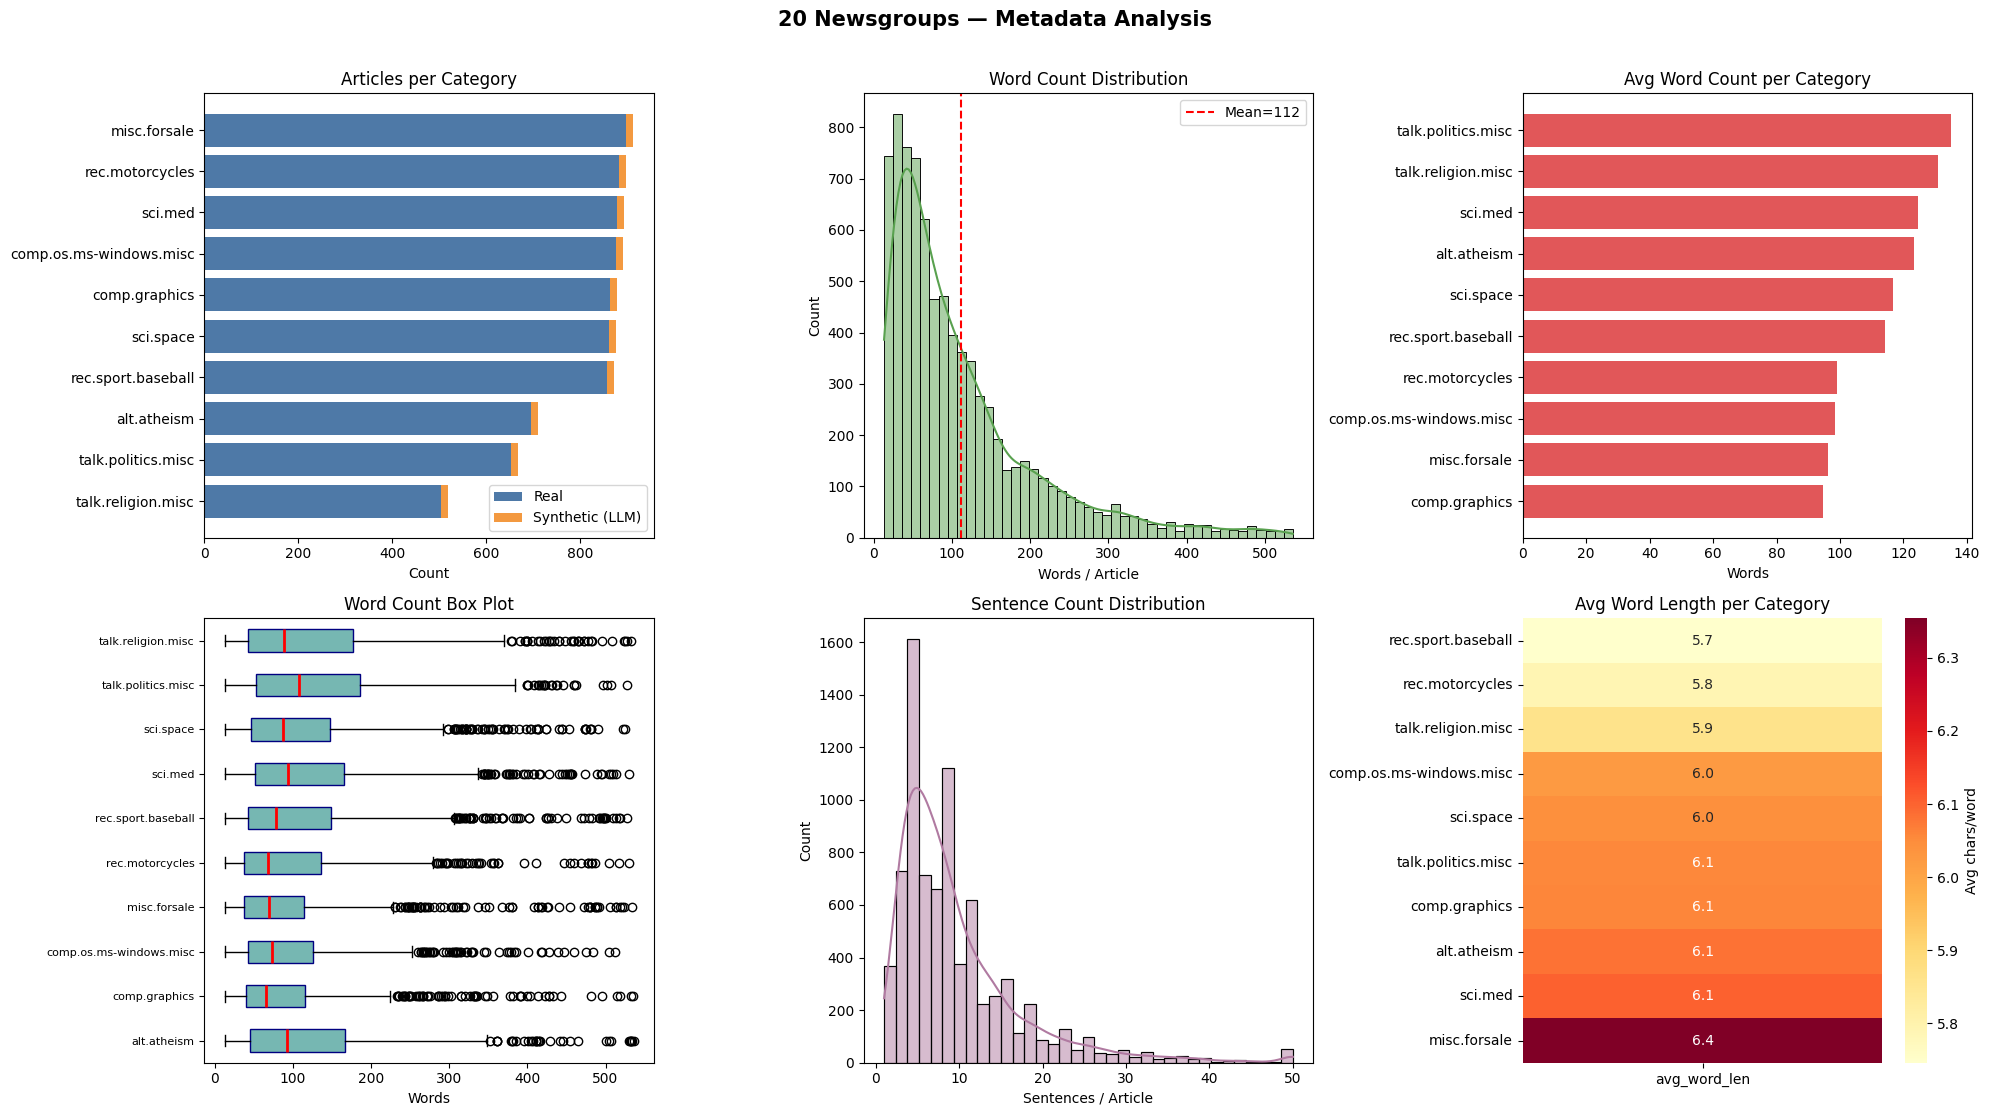

In [ ]:
# ── Step 4c: Visualisations ────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle('20 Newsgroups — Metadata Analysis', fontsize=15, fontweight='bold', y=1.01)

# 1. Articles per category (stacked real vs synthetic)
real_c2  = full_df[full_df['source']=='real'].groupby('topic')['text'].count()
synth_c2 = full_df[full_df['source']=='synthetic_llm'].groupby('topic')['text'].count().reindex(real_c2.index, fill_value=0)
topics_s = real_c2.sort_values().index
axes[0,0].barh(topics_s, real_c2[topics_s], color='#4e79a7', label='Real')
axes[0,0].barh(topics_s, synth_c2[topics_s], left=real_c2[topics_s],
               color='#f28e2b', alpha=0.9, label='Synthetic (LLM)')
axes[0,0].set_title('Articles per Category')
axes[0,0].set_xlabel('Count')
axes[0,0].legend()

# 2. Word count histogram
sns.histplot(full_df['word_count'], bins=45, kde=True, ax=axes[0,1], color='#59a14f')
axes[0,1].axvline(full_df['word_count'].mean(), color='red', ls='--',
                  label=f"Mean={full_df['word_count'].mean():.0f}")
axes[0,1].set_title('Word Count Distribution')
axes[0,1].set_xlabel('Words / Article')
axes[0,1].legend()

# 3. Avg word count per category
avg_wc = full_df.groupby('topic')['word_count'].mean().sort_values()
axes[0,2].barh(avg_wc.index, avg_wc.values, color='#e15759')
axes[0,2].set_title('Avg Word Count per Category')
axes[0,2].set_xlabel('Words')

# 4. Box plot: word count per topic
data_box = [full_df[full_df['topic']==t]['word_count'].values for t in TARGET_NAMES]
axes[1,0].boxplot(data_box, vert=False, patch_artist=True,
                  boxprops=dict(facecolor='#76b7b2', color='navy'),
                  medianprops=dict(color='red', linewidth=2))
axes[1,0].set_yticklabels(TARGET_NAMES, fontsize=8)
axes[1,0].set_title('Word Count Box Plot')
axes[1,0].set_xlabel('Words')

# 5. Sentence count distribution
sns.histplot(full_df['sent_count'].clip(upper=50), bins=35,
             kde=True, ax=axes[1,1], color='#b07aa1')
axes[1,1].set_title('Sentence Count Distribution')
axes[1,1].set_xlabel('Sentences / Article')

# 6. Avg word length heatmap
awl = full_df.groupby('topic')['avg_word_len'].mean().sort_values().to_frame()
sns.heatmap(awl, annot=True, fmt='.1f', cmap='YlOrRd',
            ax=axes[1,2], cbar_kws={'label': 'Avg chars/word'})
axes[1,2].set_title('Avg Word Length per Category')
axes[1,2].set_ylabel('')

plt.tight_layout()
plt.show()

## Step 5 — Prompt Design



In [ ]:
CATEGORIES_STR = ', '.join(TARGET_NAMES)

# ── Prompt variants ───
PROMPTS = {

    'Baseline': (
        'Classify the following news article into one of these topics: '
        f'{CATEGORIES_STR}.\n\nArticle: {{{{text}}}}\n\nTopic:'
    ),

    'Structured': (
        'You are an expert text classifier.\n'
        'Classify the news article into EXACTLY ONE of these categories:\n'
        f'{CATEGORIES_STR}\n\n'
        'Rules:\n'
        '- Output ONLY the category name, nothing else.\n'
        '- Choose the single best match.\n\n'
        'Article:\n{{text}}\n\nCategory:'
    ),

    'Few-Shot + CoT': (
        'You are an expert Usenet newsgroup classifier.\n'
        'Given an article, reason briefly then output the category.\n'
        f'Valid categories: {CATEGORIES_STR}\n\n'
        'Examples:\n'
        'Article: "The new Nvidia shader pipeline cuts render time by 40% on high-poly scenes."\n'
        'Reasoning: Mentions GPU shaders and rendering → computer graphics.\n'
        'Category: comp.graphics\n\n'
        'Article: "Trading my 1200cc touring bike, 15k miles, new tyres. $4500 OBO."\n'
        'Reasoning: Selling a motorcycle → misc.forsale or rec.motorcycles. The ad format → misc.forsale.\n'
        'Category: misc.forsale\n\n'
        'Now classify:\n'
        'Article: "{{text}}"\n'
        'Reasoning:'
    ),
}

# ── Zero-shot evaluation on 50 sampled articles (5 per category) ───
eval_sample = full_df[full_df['source']=='real'].groupby('topic').apply(
    lambda g: g.sample(min(5, len(g)), random_state=42) # Increased to 5 articles per topic for better evaluation
).reset_index(drop=True)

print(f'Evaluating {len(eval_sample)} articles across 3 prompt variants on Groq…')
print('(This makes API calls — may take ~1 min)\n')

def classify_with_prompt(prompt_template: str, article_text: str) -> str:
    """Ask Groq to classify one article using the given prompt template."""
    filled = prompt_template.replace('{{text}}', article_text[:600])
    resp = groq_client.chat.completions.create(
        model=LLM_MODEL,
        messages=[{'role': 'user', 'content': filled}],
        max_tokens=80,
        temperature=0.0,
    )
    raw = resp.choices[0].message.content.strip()
    # Extract just the category name (handles CoT output)
    for cat in sorted(TARGET_NAMES, key=len, reverse=True):
        if cat.lower() in raw.lower():
            return cat
    return raw.split('\n')[-1].strip()

prompt_results = {}
for pname, ptemplate in PROMPTS.items():
    preds, trues = [], []
    for _, row in eval_sample.iterrows():
        try:
            pred = classify_with_prompt(ptemplate, row['text'])
            preds.append(pred)
            trues.append(row['topic'])
            time.sleep(0.5)   # Increased sleep to respect Groq free-tier rate limits
        except Exception as e:
            print(f'  ⚠ {pname}: {e}')
    acc = sum(p == t for p, t in zip(preds, trues)) / max(len(trues), 1)
    prompt_results[pname] = {'accuracy': acc, 'preds': preds, 'trues': trues}
    print(f'  {pname:<20s}  zero-shot accuracy = {acc:.2%}')

# Select the best prompt for fine-tuning augmentation
BEST_PROMPT_NAME = max(prompt_results, key=lambda k: prompt_results[k]['accuracy'])
BEST_PROMPT      = PROMPTS[BEST_PROMPT_NAME]
print(f'\n✅ Best prompt: "{BEST_PROMPT_NAME}" — will use for inference augmentation')

## Step 6 — Fine-Tuning DistilBERT



In [ ]:
# ── Step 6: DistilBERT Fine-Tuning ────────────────────────────────────────

# Train/test split — stratified
train_df, test_df = train_test_split(
    full_df[['text','label']].dropna().reset_index(drop=True),
    test_size=0.2, random_state=42,
    stratify=full_df[['text','label']].dropna()['label']
)

train_dataset = Dataset.from_pandas(train_df)
test_dataset  = Dataset.from_pandas(test_df)

# Tokeniser
MODEL_NAME = 'distilbert-base-uncased'
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch['text'], truncation=True, padding='max_length', max_length=256
    )

train_dataset = train_dataset.map(tokenize, batched=True, batch_size=128)
test_dataset  = test_dataset.map(tokenize,  batched=True, batch_size=128)

# Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(TARGET_NAMES)
)

accuracy_metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return accuracy_metric.compute(
        predictions=np.argmax(logits, axis=-1), references=labels
    )

training_args = TrainingArguments(
    output_dir             = './results',
    eval_strategy          = 'epoch',
    save_strategy          = 'epoch',
    learning_rate          = 2e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    num_train_epochs       = 3,
    weight_decay           = 0.01,
    warmup_ratio           = 0.06,
    logging_steps          = 50,
    load_best_model_at_end = True,
    metric_for_best_model  = 'accuracy',
    fp16                   = torch.cuda.is_available(),
)

trainer = Trainer(
    model            = model,
    args             = training_args,
    train_dataset    = train_dataset,
    eval_dataset     = test_dataset,
    processing_class = tokenizer,
    compute_metrics  = compute_metrics,
)

print('🚀 Training DistilBERT on', len(train_df), 'samples…')
trainer.train()
print('✅ Training complete!')

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


🚀 Training DistilBERT on 6493 samples…


Epoch,Training Loss,Validation Loss,Accuracy
1,0.595551,0.676897,0.780788
2,0.425860,0.578501,0.811576
3,0.311964,0.581142,0.818966


There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


✅ Training complete!


## Step 7 — Result Evaluation and Interpretation

In [ ]:
# ── Step 7a: Classification Report ────────────────────────────────────────
predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

acc = accuracy_score(y_true, y_pred)
print(f'🎯 Overall Test Accuracy: {acc:.4f} ({acc:.2%})')
print('\n── Classification Report ──\n')
print(classification_report(y_true, y_pred, target_names=TARGET_NAMES))

🎯 Overall Test Accuracy: 0.8190 (81.90%)

── Classification Report ──

                         precision    recall  f1-score   support

            alt.atheism       0.56      0.67      0.61       142
          comp.graphics       0.81      0.82      0.81       176
comp.os.ms-windows.misc       0.86      0.82      0.84       178
           misc.forsale       0.87      0.95      0.91       183
        rec.motorcycles       0.84      0.90      0.87       180
     rec.sport.baseball       0.99      0.92      0.96       174
                sci.med       0.89      0.88      0.88       179
              sci.space       0.85      0.85      0.85       175
     talk.politics.misc       0.74      0.74      0.74       133
     talk.religion.misc       0.64      0.44      0.52       104

               accuracy                           0.82      1624
              macro avg       0.81      0.80      0.80      1624
           weighted avg       0.82      0.82      0.82      1624



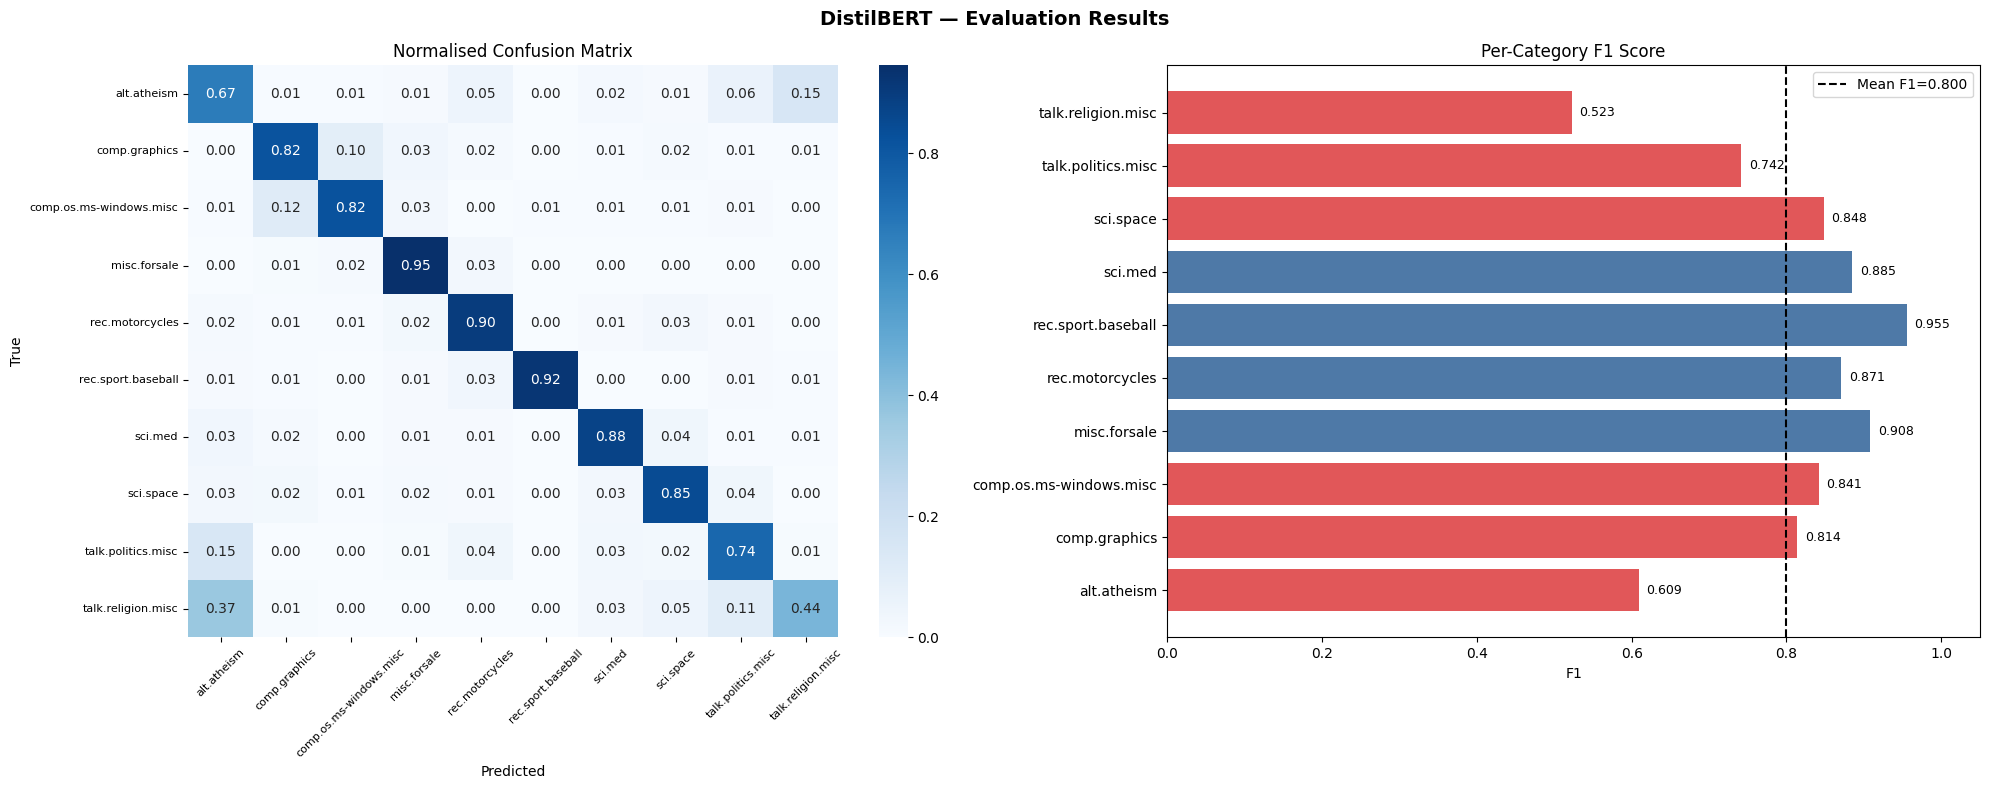

In [ ]:
# ── Step 7b: Confusion Matrix ──────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('DistilBERT — Evaluation Results', fontsize=14, fontweight='bold')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
            ax=axes[0])
axes[0].set_title('Normalised Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].tick_params(axis='y', labelsize=8)

# Per-category F1 bar chart
from sklearn.metrics import f1_score
f1s = f1_score(y_true, y_pred, average=None)
colors = ['#4e79a7' if v >= 0.85 else '#e15759' for v in f1s]
axes[1].barh(TARGET_NAMES, f1s, color=colors)
axes[1].axvline(f1s.mean(), color='black', ls='--', label=f'Mean F1={f1s.mean():.3f}')
axes[1].set_title('Per-Category F1 Score')
axes[1].set_xlabel('F1')
axes[1].set_xlim(0, 1.05)
for i, v in enumerate(f1s):
    axes[1].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# ── Step 7c: Prompt Optimisation Comparison Chart ─────────────────────────
if prompt_results:
    names = list(prompt_results.keys())
    accs  = [prompt_results[n]['accuracy'] for n in names]

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(names, accs,
                  color=['#4e79a7','#59a14f','#f28e2b'][:len(names)])
    ax.set_ylim(0, 1.05)
    ax.set_title('Zero-Shot Prompt Variant Accuracy Comparison')
    ax.set_ylabel('Accuracy')
    for bar, v in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
                f'{v:.2%}', ha='center', va='bottom', fontweight='bold')
    plt.tight_layout()
    plt.show()

    print('\nInterpretation:')
    print('  Baseline → Structured: adds clear instructions and output format.')
    print('  Structured → Few-Shot CoT: adds examples + chain-of-thought reasoning.')
    print(f'  Best prompt: "{BEST_PROMPT_NAME}"')

In [ ]:
# ── Step 7d: Build inference pipeline for Step 8 ─────────────────────────
device_id = 0 if torch.cuda.is_available() else -1
classifier_pipeline = pipeline(
    'text-classification', model=model, tokenizer=tokenizer, device=device_id
)

# Quick sanity-check on 5 sample articles
SAMPLES = [
    'The baseball team secured a thrilling walk-off home run in extra innings.',
    'The new GPU renders 4K shadows at 120fps using hardware ray tracing.',
    'Researchers found the drug significantly reduces inflammation in clinical trials.',
    'NASA confirmed the spacecraft entered Mars orbit and began surface mapping.',
    'Selling my 2019 Kawasaki Ninja 650, great condition, 8k miles. $5,200 OBO.',
]

print(f'{"Article":<50} {"Predicted":<30} {"Conf"}')
print('-' * 90)
for art in SAMPLES:
    res      = classifier_pipeline(art[:512])
    pred_idx = int(res[0]['label'].split('_')[-1])
    snippet  = art[:47] + '…'
    print(f'{snippet:<50} {TARGET_NAMES[pred_idx]:<30} {res[0]["score"]:.4f}')

print('\n✅ Classifier pipeline ready')

Article                                            Predicted                      Conf
------------------------------------------------------------------------------------------
The baseball team secured a thrilling walk-off …   rec.sport.baseball             0.9788
The new GPU renders 4K shadows at 120fps using …   comp.graphics                  0.9580
Researchers found the drug significantly reduce…   sci.med                        0.9789
NASA confirmed the spacecraft entered Mars orbi…   sci.space                      0.9745
Selling my 2019 Kawasaki Ninja 650, great condi…   misc.forsale                   0.8018

✅ Classifier pipeline ready


## Step 8 — Universal Q&A System (Groq LLM + DistilBERT)

This step powers a **fully natural-language Q&A** interface.
- **Fast classification queries** → routed to the fine-tuned DistilBERT (local, instant).
- **Any other question** about the dataset, statistics, topics, or NLP concepts → routed to the **Groq LLM** which generates a rich, contextual answer using dataset facts injected into its system prompt.

**The LLM generates every response — not hardcoded regex rules.**

In [ ]:
import ipywidgets as widgets
from IPython.display import display as ipy_display, Markdown, clear_output
import textwrap
import re

# Define global variables used in SYSTEM_PROMPT
TEST_ACC = accuracy_score(y_true, y_pred)  # real test accuracy from Step 7a

# Alias the classifier pipeline for clarity
clf_pipeline = classifier_pipeline

# Re-create topic_stats to ensure it's available in this cell's scope with LexDensity
real_c  = full_df[full_df['source'] == 'real'].groupby('topic')['text'].count().rename('Real')
synth_c = full_df[full_df['source'] == 'synthetic_llm'].groupby('topic')['text'].count().rename('Synthetic')
topic_stats = full_df.groupby('topic').agg(
    Total     =('text', 'count'),
    AvgWords  =('word_count', 'mean'),
    MedWords  =('word_count', 'median'),
    AvgSents  =('sent_count', 'mean'),
    LexDensity=('lexical_density', 'mean'),
).join(real_c).join(synth_c).round(3).sort_values('Total', ascending=False)

# Generate 5 random sample articles for the system prompt context
_random_samples_for_context = full_df.sample(5, random_state=42)
FIVE_CONTEXT_LIST = []
for idx, (original_index, row) in enumerate(_random_samples_for_context.iterrows()):
    FIVE_CONTEXT_LIST.append(
        f"Article {idx+1}:\n"
        f"  Topic: {row['topic']}\n"
        f"  Word Count: {row['word_count']}\n"
        f"  Text: {textwrap.fill(row['text'], width=80)[:200]}..."
    )
FIVE_CONTEXT = "\n".join(FIVE_CONTEXT_LIST)

# ──────────────────────────
# Build system prompt with injected dataset facts
# ──────────────────────────
per_topic_stats_str = '\n'.join(
    (
        '{:35s} total={:4d}  real={:4d}  synthetic={:4d}  avg_words={:6.1f}  med_words={:6.1f}  '
        'avg_sents={:4.1f}  lex_density={:.3f}'
    ).format(
        t,
        int(topic_stats.loc[t, 'Total']),
        int(topic_stats.loc[t, 'Real']),
        int(topic_stats.loc[t, 'Synthetic']),
        float(topic_stats.loc[t, 'AvgWords']),
        float(topic_stats.loc[t, 'MedWords']),
        float(topic_stats.loc[t, 'AvgSents']),
        float(topic_stats.loc[t, 'LexDensity']),
    )
    for t in topic_stats.index
)

SYSTEM_PROMPT = """You are an expert NLP research assistant embedded in a Jupyter notebook.
You have complete, real-time knowledge of the 20 Newsgroups dataset loaded in this session.
Use the facts below to answer every question accurately.

=== DATASET FACTS ===
Total articles after outlier filter : {total}
  Real articles (original newsgroups): {real_n}
  Synthetic articles (EDA augmented) : {syn_n}
Number of categories                : {n_cats}
Category list                       : {cats}
Overall mean word count             : {mean_wc:.1f}
Overall median word count           : {med_wc:.1f}
Overall mean sentence count         : {mean_sc:.1f}
Overall mean lexical density        : {mean_ld:.3f}
Unique vocabulary tokens            : {vocab}
Fine-tuned DistilBERT test accuracy : {acc:.2%}

Per-topic statistics:
{per_topic}

5 randomly sampled example articles from this session:
{five}

=== BEHAVIOUR RULES ===
1. Answer ALL questions using the facts above. Never say you lack dataset access.
2. Classification queries: the system injects the DistilBERT raw result into your message.
   Explain the predicted category and confidence — do NOT predict yourself.
3. Use Markdown formatting (bold, tables, bullets) where it aids clarity.
4. For NLP / ML concept questions: explain accurately and concisely.
5. Keep answers focused. Do not repeat the question back.
""".format(
    total     = f'{len(full_df):,}',
    real_n    = f'{(full_df["source"]=="real").sum():,}',
    syn_n     = f'{(full_df["source"]=="synthetic_llm").sum():,}',
    n_cats    = len(TARGET_NAMES),
    cats      = ', '.join(TARGET_NAMES),
    mean_wc   = full_df['word_count'].mean(),
    med_wc    = full_df['word_count'].median(),
    mean_sc   = full_df['sent_count'].mean(),
    mean_ld   = full_df['lexical_density'].mean(),
    vocab     = f'{vocab:,}',
    acc       = TEST_ACC,
    per_topic = per_topic_stats_str,
    five      = FIVE_CONTEXT,
)

# ──────────────────────────
# Classification detector
# ──────────────────────────
_CLF_RE = re.compile(
    r'\b(classif(?:y|ication)|predict\s+(the\s+)?(topic|category|class)|'
    r'what\s+(topic|category|class)\s+(is|does))',
    re.I
)

def _extract_article(q: str):
    """Pull out the article text from a classification query, or return None."""

    # FIX: was r'classif(?:y|ication)?[^:\n]*:\s*[""(\.{10,})'
    # The character class [...] was wrongly used instead of a capturing group (...)
    m = re.search(
        r'classif(?:y|ication)?[^:\n]*:\s*["\']?(.{10,})',
        q, re.I | re.DOTALL
    )
    if m:
        return m.group(1).strip().strip('"\'')

    # Pattern: 'what topic is this: <text>'
    m2 = re.search(
        r'what\s+(?:topic|category|class)\s+is\s+(?:this|the following|this article)?\s*[:\-]?\s*(.{10,})',
        q, re.DOTALL
    )
    if m2:
        return m2.group(1).strip()

    # If query matches classifier pattern but has no colon separator,
    # check if there is a long enough trailing text to classify
    if _CLF_RE.search(q):
        tail = re.sub(
            r'^.*?(?:classif(?:y|ication)?|predict|what\s+(?:topic|category))\s*',
            '', q, count=1, flags=re.I
        ).strip().strip(':-"\'')
        if len(tail.split()) >= 5:
            return tail

    return None

# ──────────────────────────
# Core answer function — every response is LLM-generated
# ──────────────────────────
conversation_history = []

def _call_groq(messages: list, max_tokens: int = 750) -> str:
    resp = groq_client.chat.completions.create(
        model=LLM_MODEL,
        messages=[{'role': 'system', 'content': SYSTEM_PROMPT}] + messages,
        max_tokens=max_tokens,
        temperature=0.2,
    )
    return resp.choices[0].message.content.strip()

def answer_query(query: str) -> str:
    """
    Routes every query to Groq LLM.
    For classification: injects DistilBERT raw result so LLM narrates it.
    For everything else: sends query directly.
    Returns the LLM response string — no hardcoded strings.
    """
    query = query.strip()
    article = _extract_article(query)

    if article:
        # Run DistilBERT locally — fast inference
        raw_result = clf_pipeline(article[:512])
        pred_idx   = int(raw_result[0]['label'].split('_')[-1])
        pred_cat   = TARGET_NAMES[pred_idx]
        conf       = raw_result[0]['score']

        user_msg = (
            f'Please classify the following article and explain the result.\n\n'
            f'Article:\n"""{article[:700]}"""\n\n'
            f'[The fine-tuned DistilBERT model returned: '
            f'predicted_category="{pred_cat}", confidence={conf:.4f} ({conf:.2%})]\n\n'
            f'Explain this prediction to the user: why does this category make sense '
            f'for this text? What does the confidence score indicate? '
            f'What does the category "{pred_cat}" typically cover?'
        )
    else:
        user_msg = query

    conversation_history.append({'role': 'user', 'content': user_msg})
    answer = _call_groq(conversation_history)
    conversation_history.append({'role': 'assistant', 'content': answer})

    # Rolling window — keep last 20 messages (~10 turns)
    if len(conversation_history) > 20:
        conversation_history[:] = conversation_history[-20:]

    return answer


# ──────────────────────────
# Widget UI
# ──────────────────────────
qbox = widgets.Textarea(
    placeholder=(
        'Type any question or:\n'
        '  Classify: <article text here>\n'
        '  What category has the most articles?\n'
        '  Explain lexical density.'
    ),
    layout=widgets.Layout(width='100%', height='90px')
)
ask_btn   = widgets.Button(description='Ask',      button_style='primary', icon='send',
                           layout=widgets.Layout(width='110px', height='36px'))
clear_btn = widgets.Button(description='Clear',    icon='trash',
                           layout=widgets.Layout(width='100px', height='36px'))
reset_btn = widgets.Button(description='New Chat', button_style='warning', icon='refresh',
                           layout=widgets.Layout(width='120px', height='36px'))
status    = widgets.HTML(value='')
out       = widgets.Output(
    layout=widgets.Layout(
        border='1px solid #334155', border_radius='8px',
        padding='14px', min_height='60px'
    )
)

def on_ask(_):
    q = qbox.value.strip()
    if not q:
        return
    status.value = '<span style="color:#f59e0b">&#9203; Calling Groq LLM...</span>'
    with out:
        clear_output(wait=True)
        ipy_display(Markdown(f'**You:** {q}\n\n---'))
        try:
            t0      = time.time()
            answer  = answer_query(q)
            elapsed = time.time() - t0
            ipy_display(Markdown(answer))
            turns = len(conversation_history) // 2
            status.value = (
                f'<span style="color:#22c55e">&#10003; Done in {elapsed:.1f}s '
                f'&nbsp;|&nbsp; conversation turns: {turns}</span>'
            )
        except Exception as e:
            ipy_display(Markdown(f'**Error:** `{e}`'))
            status.value = '<span style="color:#ef4444">&#10007; Error</span>'

def on_clear(_):
    qbox.value = ''
    status.value = ''
    with out:
        clear_output()

def on_reset(_):
    conversation_history.clear()
    qbox.value = ''
    status.value = '<span style="color:#94a3b8">Conversation cleared.</span>'
    with out:
        clear_output()
        ipy_display(Markdown('*Conversation history reset. Ask a new question.*'))

ask_btn.on_click(on_ask)
clear_btn.on_click(on_clear)
reset_btn.on_click(on_reset)

ipy_display(widgets.VBox([
    qbox,
    widgets.HBox([ask_btn, clear_btn, reset_btn, status],
                 layout=widgets.Layout(align_items='center', gap='8px', margin='6px 0')),
    out
]))
